# IoU Threshold Plot

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
datasets_color = {'BBBC039':'#FFC0CB',
                   'mnfinder_test':'#80ED99',
                   'mnDINO_data_01':'#192A56',
                   'mnDINO_data_02':'#00A3FF'}

methods_color = {'mnDINO':'#00B4D8',
                  'MNFinder':'#4F00BC',
                  'MicroNucML':'#9900ffff',
                  'UNet':'#e22f80ff',
                  'CP-SAM':'#D90429',
                  'Cellpose3':'#ff8f00ff',
                  'microSAM':'#FFC300'}

objects_color = {'Nuc':'#00A3FF',
                 'MN':'#A68CFF'}


# Add a column called iou_threshold, iterate through all csvs and concatenate into one.

In [4]:
folder_path = '/scr/yren/IoUs'
result_files = [file for file in os.listdir(folder_path) if file.endswith('.csv')]

all_result = pd.DataFrame()
for file in result_files:
    threshold = file.removeprefix('results_').removesuffix('.csv')
    result = pd.read_csv(os.path.join(folder_path, file))
    all_result = pd.concat([all_result, result])

In [12]:
from matplotlib.ticker import PercentFormatter

In [2]:
all_result = pd.read_csv('/scr/yren/iou_threshold.csv')

In [14]:
# Level 1: aggregate on methods & datasets
summary = all_result.groupby(['methods', 'datasets', 'iou_threshold']).mean('f1').reset_index()

# Level 2: aggregate on methods over 4 aggregated datasets F1 scores
table = summary.groupby(['methods', 'iou_threshold']).mean('f1').reset_index()
table[table.methods == 'mnDINO']

,methods,iou_threshold,iou_score,precision,recall,f1
54,mnDINO,0.1,0.486976,0.750930,0.824363,0.772795
55,mnDINO,0.2,0.486976,0.739997,0.806672,0.759154
56,mnDINO,0.3,0.486976,0.724109,0.780553,0.738350
57,mnDINO,0.4,0.486976,0.700196,0.749088,0.711457
58,mnDINO,0.5,0.486976,0.619926,0.656320,0.627329
59,mnDINO,0.6,0.486976,0.518779,0.548108,0.526462
60,mnDINO,0.7,0.486976,0.322604,0.338809,0.327941
61,mnDINO,0.8,0.486976,0.087001,0.091839,0.088981
62,mnDINO,0.9,0.486976,0.004615,0.004895,0.004727


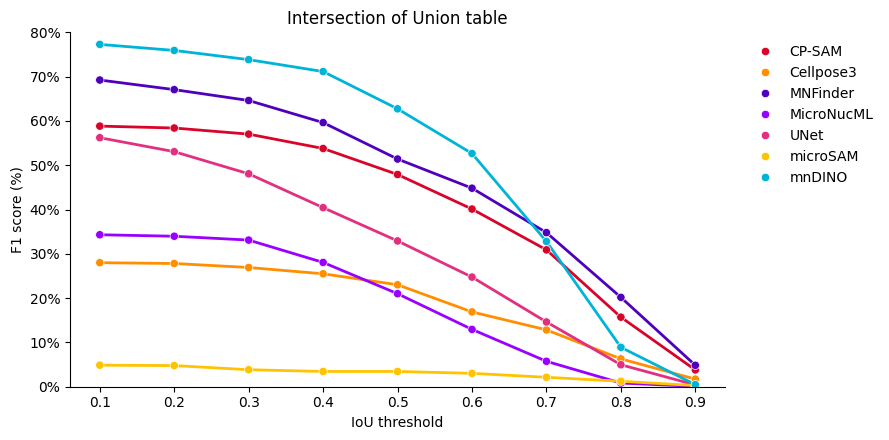

In [22]:
plt.figure(figsize=(9, 4.5))

# Lines only (no markers, no legend of their own)
ax = sns.lineplot(data=table, 
                  x='iou_threshold', 
                  y='f1', 
                  hue='methods', 
                  palette=methods_color,
                  linewidth=2, 
                  legend=False)

# Dots whose size follows the F1 score
sns.scatterplot(data=table, x='iou_threshold', y='f1', hue='methods', ax=ax, zorder=3, palette=methods_color)

ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set_xlabel('IoU threshold')
ax.set_ylabel('F1 score (%)')
ax.set_xticks(sorted(table['iou_threshold'].unique()))
ax.set_ylim(0, 0.8)
ax.legend(title=None, bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
sns.despine()
plt.title('Intersection of Union table')
plt.tight_layout()
plt.show()

# IoU Scores Averaged by Methods

In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [7]:
# all_result.to_csv('/scr/yren/iou_threshold.csv', index=False)

In [16]:
table

,methods,iou_threshold,iou_score,precision,recall,f1
0,CP-SAM,0.1,0.431876,0.640077,0.569905,0.588311
1,CP-SAM,0.2,0.431876,0.634476,0.566469,0.584016
2,CP-SAM,0.3,0.431876,0.618316,0.553920,0.570216
3,CP-SAM,0.4,0.431876,0.582826,0.523699,0.537780
4,CP-SAM,0.5,0.431876,0.519465,0.464693,0.479084
...,...,...,...,...,...,...
58,mnDINO,0.5,0.486976,0.619926,0.656320,0.627329
59,mnDINO,0.6,0.486976,0.518779,0.548108,0.526462
60,mnDINO,0.7,0.486976,0.322604,0.338809,0.327941
61,mnDINO,0.8,0.486976,0.087001,0.091839,0.088981


In [17]:
table[table.iou_threshold == 0.1].groupby('methods')['iou_score'].mean().sort_values(ascending=False).index

Index(['mnDINO', 'MNFinder', 'CP-SAM', 'Cellpose3', 'MicroNucML', 'UNet',
       'microSAM'],
      dtype='object', name='methods')

/tmp/ipykernel_2402393/2620236689.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(table[table.iou_threshold==0.1], x='methods', y='iou_score', order=order, palette=methods_color, legend=False)


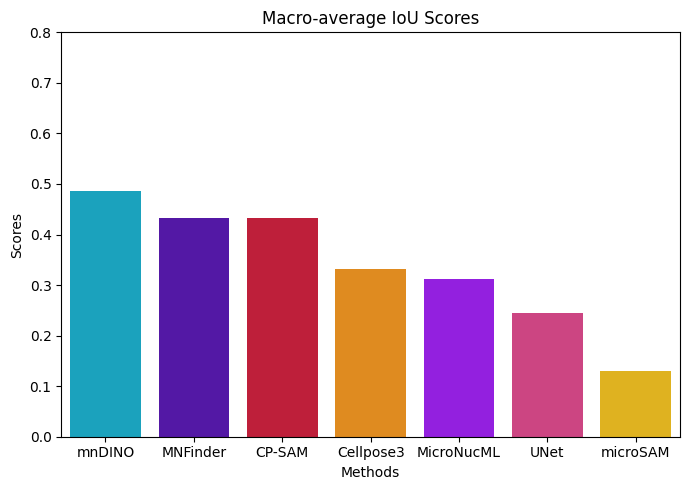

In [23]:
order = table[table.iou_threshold == 0.1].groupby('methods')['iou_score'].mean().sort_values(ascending=False).index
plt.figure(figsize=(7, 5))
ax = sns.barplot(table[table.iou_threshold==0.1], x='methods', y='iou_score', order=order, palette=methods_color, legend=False)
# for container in ax.containers:
#     ax.bar_label(container, fmt='%.3f', padding=3)
ax.set_ylim(0, 0.8)

plt.title('Macro-average IoU Scores')
plt.xlabel('Methods')
plt.ylabel('Scores')
plt.tight_layout()
plt.show()

- Report Average IoU scores at 0.1 for all methods

In [25]:
all_result[all_result.iou_threshold == 0.1].groupby(['methods']).mean('iou_score')

,iou_threshold,iou_score,precision,recall,f1
methods,,,,,
CP-SAM,0.1,0.282245,0.394428,0.446577,0.394562
Cellpose3,0.1,0.170747,0.242466,0.200045,0.171678
MNFinder,0.1,0.378208,0.587086,0.797731,0.650438
MicroNucML,0.1,0.140856,0.249459,0.112864,0.151217
UNet,0.1,0.193722,0.390100,0.779270,0.492909
microSAM,0.1,0.078659,0.114266,0.034439,0.037003
mnDINO,0.1,0.393209,0.659334,0.787930,0.694903


## IoU Scores Averaged by Datasets

In [11]:
all_result[all_result.iou_threshold == 0.1].groupby(['methods', 'datasets']).mean('iou_score')

iou_threshold  iou_score  precision    recall  \
methods    datasets                                                        
CP-SAM     BBBC039                   0.1   0.133507   0.206563  0.345807   
           mnDINO_data_01            0.1   0.553167   0.767400  0.632800   
           mnDINO_data_02            0.1   0.427850   0.808750  0.643100   
           mnfinder_test             0.1   0.612981   0.777594  0.657913   
Cellpose3  BBBC039                   0.1   0.064428   0.095928  0.201944   
           mnDINO_data_01            0.1   0.473100   0.662900  0.251200   
           mnDINO_data_02            0.1   0.421200   0.762750  0.269450   
           mnfinder_test             0.1   0.368481   0.492419  0.176675   
MNFinder   BBBC039                   0.1   0.286547   0.510498  0.821616   
           mnDINO_data_01            0.1   0.422767   0.635067  0.727533   
           mnDINO_data_02            0.1   0.412900   0.703500  0.802350   
           mnfinder_test             0.1   0.611856   0.769369  0.746125   
MicroNucML BBBC039                   0.1   0.000000   0.000000  0.000000   
           mnDINO_data_01            0.1   0.433500   0.742967  0.250600   
           mnDINO_data_02            0.1   0.383700   0.765700  0.408100   
           mnfinder_test             0.1   0.434181   0.762819  0.353456   
UNet       BBBC039                   0.1   0.156326   0.338695  0.771388   
           mnDINO_data_01            0.1   0.288367   0.541733  0.863567   
           mnDINO_data_02            0.1   0.266550   0.423800  0.895150   
           mnfinder_test             0.1   0.267375   0.495606  0.770162   
microSAM   BBBC039                   0.1   0.015747   0.027400  0.033851   
           mnDINO_data_01            0.1   0.189633   0.327767  0.043733   
           mnDINO_data_02            0.1   0.089250   0.222200  0.017100   
           mnfinder_test             0.1   0.225606   0.294194  0.036444   
mnDINO     BBBC039                   0.1   0.320493   0.577772  0.791979   
           mnDINO_data_01            0.1   0.520200   0.794767  0.876767   
           mnDINO_data_02            0.1   0.563700   0.795000  0.879800   
           mnfinder_test             0.1   0.543512   0.836181  0.748906   

                                 f1  
methods    datasets                  
CP-SAM     BBBC039         0.245235  
           mnDINO_data_01  0.691933  
           mnDINO_data_02  0.716150  
           mnfinder_test   0.699925  
Cellpose3  BBBC039         0.120237  
           mnDINO_data_01  0.357400  
           mnDINO_data_02  0.395150  
           mnfinder_test   0.247169  
MNFinder   BBBC039         0.611521  
           mnDINO_data_01  0.674700  
           mnDINO_data_02  0.744450  
           mnfinder_test   0.738725  
MicroNucML BBBC039         0.000000  
           mnDINO_data_01  0.373533  
           mnDINO_data_02  0.530150  
           mnfinder_test   0.468562  
UNet       BBBC039         0.451960  
           mnDINO_data_01  0.660267  
           mnDINO_data_02  0.575100  
           mnfinder_test   0.561306  
microSAM   BBBC039         0.025588  
           mnDINO_data_01  0.076533  
           mnDINO_data_02  0.031750  
           mnfinder_test   0.060925  
mnDINO     BBBC039         0.648330  
           mnDINO_data_01  0.833567  
           mnDINO_data_02  0.832400  
           mnfinder_test   0.776881

In [26]:
table[table.iou_threshold == 0.1]

,methods,iou_threshold,iou_score,precision,recall,f1
0,CP-SAM,0.1,0.431876,0.640077,0.569905,0.588311
9,Cellpose3,0.1,0.331802,0.503499,0.224817,0.279989
18,MNFinder,0.1,0.433517,0.654608,0.774406,0.692349
27,MicroNucML,0.1,0.312845,0.567871,0.253039,0.343061
36,UNet,0.1,0.244654,0.449959,0.825067,0.562158
45,microSAM,0.1,0.130059,0.217890,0.032782,0.048699
54,mnDINO,0.1,0.486976,0.750930,0.824363,0.772795


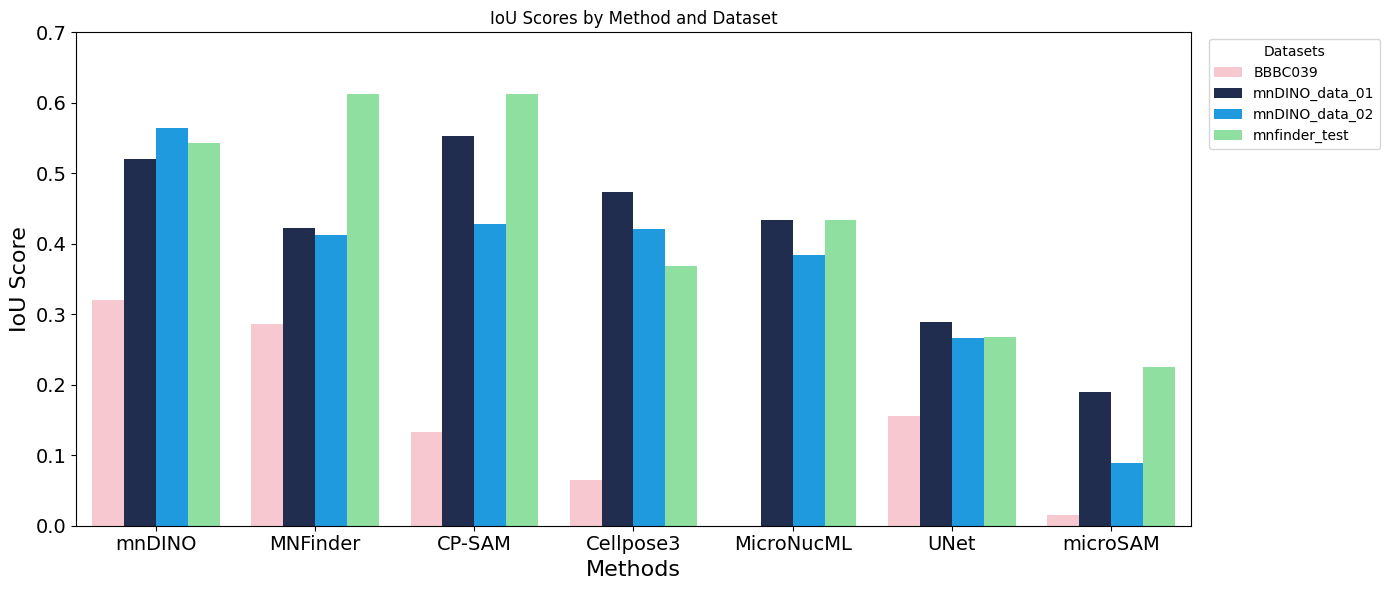

In [ ]:
all_result[all_result.iou_threshold == 0.1].groupby(['methods', 'datasets']).mean('iou_score').reset_index()plot_df = 

# order methods by their mean IoU across datasets (highest first)
order = plot_df.groupby('methods')['iou_score'].mean().sort_values(ascending=False).index

plt.figure(figsize=(14, 6))
ax = sns.barplot(plot_df, x='methods', y='iou_score', hue='datasets', palette=datasets_color, order=order)

# for container in ax.containers:
#     ax.bar_label(container, fmt='%.2f', padding=1, fontsize=8, rotation=45)

ax.set_ylim(0, 0.7)
ax.tick_params(axis='both', labelsize=14)
ax.legend(title='Datasets', bbox_to_anchor=(1.01, 1), loc='upper left')

plt.title('IoU Scores by Method and Dataset')
plt.xlabel('Methods', fontsize=16)
plt.ylabel('IoU Score', fontsize=16)
plt.tight_layout()
plt.show()

- Do macro-average way

In [27]:
table[table.iou_threshold == 0.1]

,methods,iou_threshold,iou_score,precision,recall,f1
0,CP-SAM,0.1,0.431876,0.640077,0.569905,0.588311
9,Cellpose3,0.1,0.331802,0.503499,0.224817,0.279989
18,MNFinder,0.1,0.433517,0.654608,0.774406,0.692349
27,MicroNucML,0.1,0.312845,0.567871,0.253039,0.343061
36,UNet,0.1,0.244654,0.449959,0.825067,0.562158
45,microSAM,0.1,0.130059,0.217890,0.032782,0.048699
54,mnDINO,0.1,0.486976,0.750930,0.824363,0.772795


/tmp/ipykernel_2402393/3717812293.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(table[table.iou_threshold == 0.1], x='methods', y='f1', palette=methods_color, order=order)


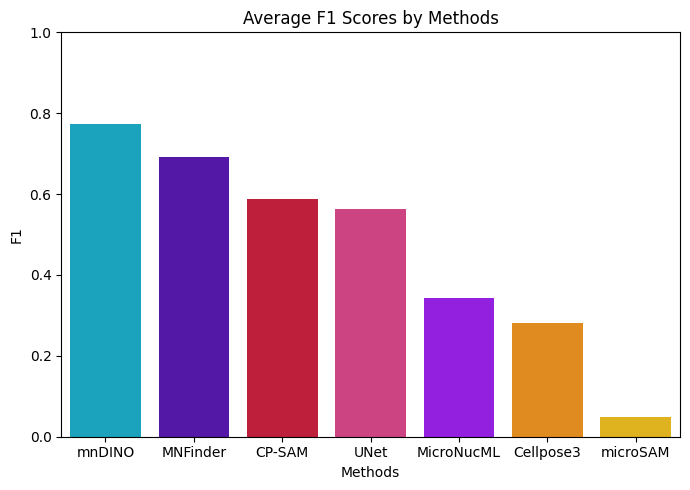

In [28]:
order = table[table.iou_threshold == 0.1].groupby('methods')['f1'].mean().sort_values(ascending=False).index
plt.figure(figsize=(7, 5))
ax = sns.barplot(table[table.iou_threshold == 0.1], x='methods', y='f1', palette=methods_color, order=order)
# for container in ax.containers:
#     ax.bar_label(container, fmt='%.3f', padding=3)
ax.set_ylim(0, 1)

plt.title('Average F1 Scores by Methods')
plt.xlabel('Methods')
plt.ylabel('F1')
plt.tight_layout()
plt.show()

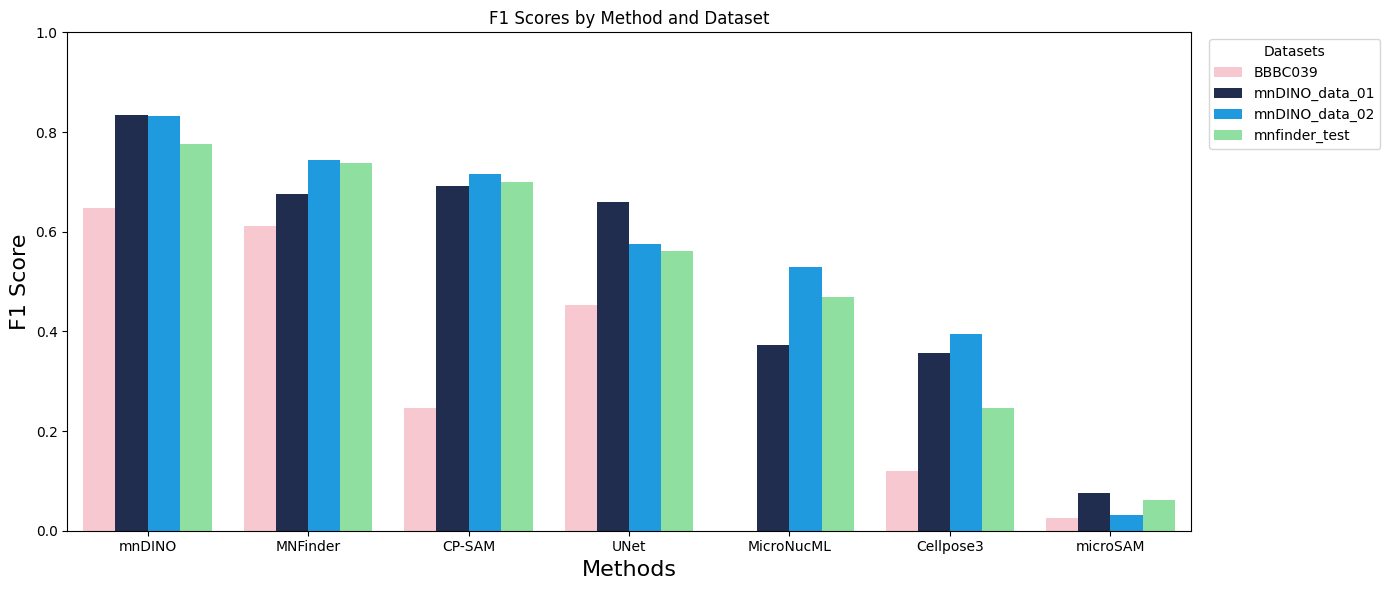

In [16]:
plot_df = all_result[all_result.iou_threshold == 0.1].groupby(['methods', 'datasets']).mean('f1').reset_index()

# order methods by their mean IoU across datasets (highest first)
order = plot_df.groupby('methods')['f1'].mean().sort_values(ascending=False).index

plt.figure(figsize=(14, 6))
ax = sns.barplot(plot_df, x='methods', y='f1', hue='datasets', palette=datasets_color, order=order)

# for container in ax.containers:
#     ax.bar_label(container, fmt='%.2f', padding=1, fontsize=8, rotation=45)

ax.set_ylim(0, 1)
ax.legend(title='Datasets', bbox_to_anchor=(1.01, 1), loc='upper left')

plt.title('F1 Scores by Method and Dataset')
plt.xlabel('Methods', fontsize=16)
plt.ylabel('F1 Score', fontsize=16)
plt.tight_layout()
plt.show()

# IoU / F1 Scores Analysis

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

- Per groups

In [4]:
all_result = pd.read_csv('/scr/yren/iou_threshold.csv')
all_result[all_result.iou_threshold == 0.1]

,imid,methods,datasets,iou_threshold,iou_score,precision,recall,f1
0,2022-10-14_U2OS-4,CP-SAM,mnfinder_test,0.1,0.5738,0.8372,0.4966,0.6234
1,2023-05-31_misc-1,CP-SAM,mnfinder_test,0.1,0.5475,0.7632,0.3973,0.5225
2,2023-05-31_misc-HFF-revt-01_s17,CP-SAM,mnfinder_test,0.1,0.7898,0.9333,0.8750,0.9032
3,2023-05-31_misc-HFF-revt-01_s18,CP-SAM,mnfinder_test,0.1,0.6634,0.8421,0.6957,0.7619
4,2023-05-31_misc-HFF-revt-01_s19,CP-SAM,mnfinder_test,0.1,0.7718,1.0000,0.7647,0.8667
...,...,...,...,...,...,...,...,...
443,IXMtest_O02_s4_w1814603DA-DD56-44EF-98C5-AFF3B...,mnDINO,BBBC039,0.1,0.1283,0.2500,1.0000,0.4000
444,IXMtest_P07_s8_w144364F25-950A-472C-A529-1A9AD...,mnDINO,BBBC039,0.1,0.2095,0.4000,0.3333,0.3636
445,IXMtest_P07_s8_w19D682C29-5685-4A33-8CAA-F0797...,mnDINO,BBBC039,0.1,0.1997,0.2500,0.2500,0.2500
446,IXMtest_P15_s8_w1D26A5BC7-CF59-4027-B785-85AD3...,mnDINO,BBBC039,0.1,0.2767,0.4286,1.0000,0.6000


In [12]:
groups = all_result[all_result.iou_threshold == 0.1].groupby(['methods', 'datasets']).mean('f1', 'iou_score')
groups

iou_threshold  iou_score  precision    recall  \
methods    datasets                                                        
CP-SAM     BBBC039                   0.1   0.133507   0.206563  0.345807   
           mnDINO_data_01            0.1   0.553167   0.767400  0.632800   
           mnDINO_data_02            0.1   0.427850   0.808750  0.643100   
           mnfinder_test             0.1   0.612981   0.777594  0.657913   
Cellpose3  BBBC039                   0.1   0.064428   0.095928  0.201944   
           mnDINO_data_01            0.1   0.473100   0.662900  0.251200   
           mnDINO_data_02            0.1   0.421200   0.762750  0.269450   
           mnfinder_test             0.1   0.368481   0.492419  0.176675   
MNFinder   BBBC039                   0.1   0.286547   0.510498  0.821616   
           mnDINO_data_01            0.1   0.422767   0.635067  0.727533   
           mnDINO_data_02            0.1   0.412900   0.703500  0.802350   
           mnfinder_test             0.1   0.611856   0.769369  0.746125   
MicroNucML BBBC039                   0.1   0.000000   0.000000  0.000000   
           mnDINO_data_01            0.1   0.433500   0.742967  0.250600   
           mnDINO_data_02            0.1   0.383700   0.765700  0.408100   
           mnfinder_test             0.1   0.434181   0.762819  0.353456   
UNet       BBBC039                   0.1   0.156326   0.338695  0.771388   
           mnDINO_data_01            0.1   0.288367   0.541733  0.863567   
           mnDINO_data_02            0.1   0.266550   0.423800  0.895150   
           mnfinder_test             0.1   0.267375   0.495606  0.770162   
microSAM   BBBC039                   0.1   0.015747   0.027400  0.033851   
           mnDINO_data_01            0.1   0.189633   0.327767  0.043733   
           mnDINO_data_02            0.1   0.089250   0.222200  0.017100   
           mnfinder_test             0.1   0.225606   0.294194  0.036444   
mnDINO     BBBC039                   0.1   0.320493   0.577772  0.791979   
           mnDINO_data_01            0.1   0.520200   0.794767  0.876767   
           mnDINO_data_02            0.1   0.563700   0.795000  0.879800   
           mnfinder_test             0.1   0.543512   0.836181  0.748906   

                                 f1  
methods    datasets                  
CP-SAM     BBBC039         0.245235  
           mnDINO_data_01  0.691933  
           mnDINO_data_02  0.716150  
           mnfinder_test   0.699925  
Cellpose3  BBBC039         0.120237  
           mnDINO_data_01  0.357400  
           mnDINO_data_02  0.395150  
           mnfinder_test   0.247169  
MNFinder   BBBC039         0.611521  
           mnDINO_data_01  0.674700  
           mnDINO_data_02  0.744450  
           mnfinder_test   0.738725  
MicroNucML BBBC039         0.000000  
           mnDINO_data_01  0.373533  
           mnDINO_data_02  0.530150  
           mnfinder_test   0.468562  
UNet       BBBC039         0.451960  
           mnDINO_data_01  0.660267  
           mnDINO_data_02  0.575100  
           mnfinder_test   0.561306  
microSAM   BBBC039         0.025588  
           mnDINO_data_01  0.076533  
           mnDINO_data_02  0.031750  
           mnfinder_test   0.060925  
mnDINO     BBBC039         0.648330  
           mnDINO_data_01  0.833567  
           mnDINO_data_02  0.832400  
           mnfinder_test   0.776881

In [14]:
groups.groupby(['methods']).mean('f1')

,iou_threshold,iou_score,precision,recall,f1
methods,,,,,
CP-SAM,0.1,0.431876,0.640077,0.569905,0.588311
Cellpose3,0.1,0.331802,0.503499,0.224817,0.279989
MNFinder,0.1,0.433517,0.654608,0.774406,0.692349
MicroNucML,0.1,0.312845,0.567871,0.253039,0.343061
UNet,0.1,0.244654,0.449959,0.825067,0.562158
microSAM,0.1,0.130059,0.217890,0.032782,0.048699
mnDINO,0.1,0.486976,0.750930,0.824363,0.772795


## Average over Objects

In [33]:
obj_result = pd.read_csv('/scr/yren/IoUs/macro_results_0.1.csv')
obj_result

,imid,methods,datasets,iou_threshold,iou_score,precision,recall,f1
0,2022-10-14_U2OS-4,CP-SAM,mnfinder_test,0.1,51.638000,0.8372,0.4966,0.6234
1,2023-05-31_misc-1,CP-SAM,mnfinder_test,0.1,20.804701,0.7632,0.3973,0.5225
2,2023-05-31_misc-HFF-revt-01_s17,CP-SAM,mnfinder_test,0.1,11.847000,0.9333,0.8750,0.9032
3,2023-05-31_misc-HFF-revt-01_s18,CP-SAM,mnfinder_test,0.1,12.605100,0.8421,0.6957,0.7619
4,2023-05-31_misc-HFF-revt-01_s19,CP-SAM,mnfinder_test,0.1,10.032900,1.0000,0.7647,0.8667
...,...,...,...,...,...,...,...,...
443,IXMtest_O02_s4_w1814603DA-DD56-44EF-98C5-AFF3B...,mnDINO,BBBC039,0.1,1.026100,0.2500,1.0000,0.4000
444,IXMtest_P07_s8_w144364F25-950A-472C-A529-1A9AD...,mnDINO,BBBC039,0.1,1.047600,0.4000,0.3333,0.3636
445,IXMtest_P07_s8_w19D682C29-5685-4A33-8CAA-F0797...,mnDINO,BBBC039,0.1,0.798800,0.2500,0.2500,0.2500
446,IXMtest_P15_s8_w1D26A5BC7-CF59-4027-B785-85AD3...,mnDINO,BBBC039,0.1,1.936700,0.4286,1.0000,0.6000


- Micro

In [34]:
summary = obj_result.groupby('methods')['iou_score'].sum().reset_index()
summary['mean_iou'] = summary['iou_score'] / 1238

summary

,methods,iou_score,mean_iou
0,CP-SAM,493.642606,0.398742
1,Cellpose3,167.371200,0.135195
2,MNFinder,665.987295,0.537954
3,MicroNucML,195.780203,0.158142
4,UNet,540.575804,0.436653
5,microSAM,28.998000,0.023423
6,mnDINO,636.788397,0.514369


- Macro

In [35]:
objs = {'BBBC039': 255, 'mnfinder_test': 473, 'mnDINO_data_01': 322, 'mnDINO_data_02': 188}

summary = obj_result.groupby(['methods', 'datasets'])['iou_score'].sum().reset_index()
summary['n_gt'] = summary['datasets'].map(objs)
summary['mean_iou'] = summary['iou_score'] / summary['n_gt']

summary

,methods,datasets,iou_score,n_gt,mean_iou
0,CP-SAM,BBBC039,59.002200,255,0.231381
1,CP-SAM,mnDINO_data_01,143.470701,322,0.445561
2,CP-SAM,mnDINO_data_02,63.743202,188,0.339060
3,CP-SAM,mnfinder_test,227.426502,473,0.480817
4,Cellpose3,BBBC039,34.744500,255,0.136253
5,Cellpose3,mnDINO_data_01,51.529300,322,0.160029
6,Cellpose3,mnDINO_data_02,30.270700,188,0.161014
7,Cellpose3,mnfinder_test,50.826700,473,0.107456
8,MNFinder,BBBC039,116.596799,255,0.457242
9,MNFinder,mnDINO_data_01,165.469196,322,0.513879


In [36]:
summary.groupby(['methods']).mean(['mean_iou'])

,iou_score,n_gt,mean_iou
methods,,,
CP-SAM,123.410651,309.5,0.374205
Cellpose3,41.842800,309.5,0.141188
MNFinder,166.496824,309.5,0.517647
MicroNucML,48.945051,309.5,0.145724
UNet,135.143951,309.5,0.447255
microSAM,7.249500,309.5,0.021147
mnDINO,159.197099,309.5,0.525175
